In [ ]:

# ==========================================
# PERSON 3: DATA CLEANING, SPLITTING
# & IMAGE PREPROCESSING
# PHASE 1
# ==========================================

# 1. Environment Setup

import os
import json
import random
import hashlib
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter, defaultdict
from PIL import Image, ImageOps
from tqdm.notebook import tqdm

from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

print("Environment initialized successfully.")


# 2. Shared Project Paths

BASE_DIR = "/content/drive/MyDrive/COCO_Project"

ANNOTATIONS_DIR = os.path.join(BASE_DIR, "annotations")
IMAGES_DIR = os.path.join(BASE_DIR, "images")
METADATA_DIR = os.path.join(BASE_DIR, "metadata")
STATISTICS_DIR = os.path.join(BASE_DIR, "statistics")

# Verify shared folders
for folder in [
    BASE_DIR,
    ANNOTATIONS_DIR,
    IMAGES_DIR,
    METADATA_DIR,
    STATISTICS_DIR
]:
    assert os.path.isdir(folder), f"Folder not found: {folder}"

print("\nShared project connected successfully!")
print("Project:", BASE_DIR)
print("Annotations:", ANNOTATIONS_DIR)
print("Images:", IMAGES_DIR)
print("Metadata:", METADATA_DIR)
print("Statistics:", STATISTICS_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Environment initialized successfully.

Shared project connected successfully!
Project: /content/drive/MyDrive/COCO_Project
Annotations: /content/drive/MyDrive/COCO_Project/annotations
Images: /content/drive/MyDrive/COCO_Project/images
Metadata: /content/drive/MyDrive/COCO_Project/metadata
Statistics: /content/drive/MyDrive/COCO_Project/statistics


In [ ]:

# ==========================================
# 2. LOAD COCO DATASET
# ==========================================

# Annotation file paths
instances_path = os.path.join(
    ANNOTATIONS_DIR,
    "instances_train2017.json"
)

captions_path = os.path.join(
    ANNOTATIONS_DIR,
    "captions_train2017.json"
)

# Verify files exist
assert os.path.exists(instances_path), "Instances file not found!"
assert os.path.exists(captions_path), "Captions file not found!"

# Load annotations
with open(instances_path, "r") as f:
    instances = json.load(f)

with open(captions_path, "r") as f:
    captions = json.load(f)

print("COCO annotation files loaded successfully!")

# Basic information
print("\n===== DATASET INFORMATION =====")

print("Images in instances file:", len(instances["images"]))
print("Object annotations:", len(instances["annotations"]))
print("Object categories:", len(instances["categories"]))

print("Images in captions file:", len(captions["images"]))
print("Human-written captions:", len(captions["annotations"]))



# 03 — Data Cleaning, Splitting and Image Preprocessing

## Image Captioning Project — MS COCO 2017

### 1. Introduction

In this part of the project, we worked on preparing the MS COCO 2017 dataset before moving to the next steps of the image captioning system.

The main goal was to organize the images, check that the data was correct, and make sure everything was ready to be used later. We also did some statistical analysis to get a better idea about the images, their captions, and the objects they contain.

Finally, we prepared the images using the CLIP processor so they can be used in the following stages of the project.

### 2. Work Objectives

The main tasks completed in this part were:

- Selecting the images needed for the project.
- Checking for missing, corrupted, or duplicate images.
- Dividing the dataset into knowledge base, validation, and test sets.
- Making sure that the different sets do not contain the same images.
- Studying image sizes and orientations.
- Analyzing caption lengths and object categories.
- Checking the number of objects in each image.
- Preparing and testing the CLIP image processor.
- Saving the results and generated files in the shared project folder.

### 3. Dataset Description

We used the MS COCO 2017 dataset. The main images were taken from `train2017`, while the separate test images were selected from `val2017`.

The dataset was organized as follows:

| Dataset | Number of images |
|---|---:|
| Knowledge Base | 10,000 |
| Validation | 100 |
| Test | 100 |
| **Total** | **10,200** |

The dataset also contains 80 object categories. The test images were selected separately from the other images to avoid overlap between the different sets.

### 4. Data Cleaning and Verification

Before using the images, we checked their quality and made sure that the annotation files were consistent with the selected image IDs.

The checks included missing files, corrupted images, duplicate images, and images without captions or object annotations.

The results for the 10,100 selected images from train2017 were:

| Check | Result |
|---|---:|
| Missing images | 0 |
| Corrupted images | 0 |
| Duplicate groups | 0 |
| Images without captions | 0 |
| Images without object annotations | 104 |

We kept the 104 images without object annotations because they still have five captions each. Since our project focuses on image captioning, these images are still useful.

### 5. Dataset Splitting

The images were divided into three separate groups.

The knowledge base contains 10,000 images and is the main collection used by the project. The validation set contains 100 images, and another 100 images were selected from COCO val2017 to create the test set.

We also downloaded the test images and checked that all of them could be opened correctly. Their corresponding captions were extracted into a separate JSON file.

The final test set contains:

- 100 images.
- 500 captions.
- 0 corrupted images.
- 0 missing captions.

We then compared the image IDs of the three sets. The result showed that there was no overlap between them.

### 6. Statistical Analysis

We performed several analyses to understand the dataset better.

**6.1 Image Dimensions**

We examined the width and height of the images and classified them according to their orientation.

| Orientation | Number of images |
|---|---:|
| Landscape | 7,328 |
| Portrait | 2,398 |
| Square | 374 |

**6.2 Caption Length**

We analyzed the captions by counting the number of words in each one.

| Measure | Result |
|---|---:|
| Total captions | 50,521 |
| Average length | 10.46 words |
| Median length | 10 words |
| Minimum length | 6 words |
| Maximum length | 47 words |

**6.3 Object Categories**

We also studied the object annotations to see which categories appear most frequently in the selected images.

There are 80 categories in total, with 72,752 object annotations. The most frequent category is `person`, with 22,319 annotations.

**6.4 Scene Complexity**

For this analysis, we counted the number of annotated objects in each image.

| Measure | Result |
|---|---:|
| Average number of objects | 7.20 |
| Median | 4 |
| Minimum | 0 |
| Maximum | 56 |

This analysis helped us see the difference between images containing only a few objects and images with more complex scenes.

### 7. Image Preprocessing with CLIP

For image preprocessing, we used the CLIP model `openai/clip-vit-base-patch32`.

We loaded its image processor and tested it on one of the selected images to make sure that the output had the correct format.

The processor performs the following operations:

- Converts the image to RGB.
- Resizes and crops it to 224 × 224 pixels.
- Rescales pixel values.
- Applies normalization using CLIP's predefined values.

The test was successful, and the output tensor had the expected shape.

| Property | Result |
|---|---|
| Original image size | 640 × 480 |
| Processed image size | 224 × 224 |
| Tensor shape | (1, 3, 224, 224) |
| Data type | float32 |
| Result | Successful |

We also saved the preprocessing configuration in a JSON file so that it can be reused in the next stage. The original images were kept unchanged.

### 8. Generated Files

During this work, we generated several files and saved them in the shared Google Drive folder.

**Metadata and reports:**

- `person3_clean_dataset_manifest.csv`
- `person3_test100_manifest.csv`
- `person3_caption_analysis.csv`
- `person3_object_category_counts.csv`
- `person3_scene_complexity.csv`
- `person3_clip_preprocessing_config.json`
- `person3_final_report.json`
- `captions_test100.json`

**Generated graphs:**

- `person3_split_distribution.png`
- `person3_image_orientation.png`
- `person3_caption_length_distribution.png`
- `person3_object_category_distribution.png`
- `person3_scene_complexity.png`

### 9. Conclusion

In this part, we prepared and checked the dataset that will be used in the image captioning project. We organized the images into three sets, checked their integrity, and performed different statistical analyses to better understand their content.

We also created a separate test set with its corresponding captions and prepared the CLIP image processor. All the important results and configuration files were saved in the shared project folder.

The dataset is now ready for the next stage, where the image embeddings and retrieval components will be handled.


In [ ]:

# ==========================================
# 3. INSPECT TEAM METADATA
# ==========================================

print("===== METADATA FILES =====")

for file in sorted(os.listdir(METADATA_DIR)):
    file_path = os.path.join(METADATA_DIR, file)

    if os.path.isfile(file_path):
        print(file)

print("\n===== IMAGE FOLDERS =====")

for folder in sorted(os.listdir(IMAGES_DIR)):
    folder_path = os.path.join(IMAGES_DIR, folder)

    if os.path.isdir(folder_path):
        print(folder, "->", len(os.listdir(folder_path)), "files")


In [ ]:

# ==========================================
# 4. INSPECT TEAM AUDIT RESULTS
# ==========================================

# Load metadata CSV files
selected_df = pd.read_csv(
    os.path.join(METADATA_DIR, "selected_image_ids.csv")
)

corrupted_df = pd.read_csv(
    os.path.join(METADATA_DIR, "corrupted_images.csv")
)

duplicates_df = pd.read_csv(
    os.path.join(METADATA_DIR, "duplicate_images.csv")
)

# Display structures
print("===== SELECTED IMAGE IDs =====")
print("Shape:", selected_df.shape)
print("Columns:", selected_df.columns.tolist())
display(selected_df.head())

print("\n===== CORRUPTED IMAGES =====")
print("Shape:", corrupted_df.shape)
print("Columns:", corrupted_df.columns.tolist())
display(corrupted_df.head())

print("\n===== DUPLICATE IMAGES =====")
print("Shape:", duplicates_df.shape)
print("Columns:", duplicates_df.columns.tolist())
display(duplicates_df.head())

# Read dataset audit report
report_path = os.path.join(
    METADATA_DIR,
    "dataset_audit_report.json"
)

with open(report_path, "r") as f:
    audit_report = json.load(f)

print("\n===== DATASET AUDIT REPORT =====")
print(json.dumps(audit_report, indent=4))


In [ ]:
# ==========================================
# 5. LOAD EXISTING IMAGE AUDIT
# ==========================================

audit_path = os.path.join(
    METADATA_DIR,
    "dataset_audit_report.json"
)

with open(audit_path, "r") as f:
    audit = json.load(f)

print("===== IMAGE INTEGRITY =====")
print("Images checked:", audit["image_integrity"]["total_images_checked"])
print("Missing images:", audit["image_integrity"]["missing_images"])
print("Corrupted images:", audit["image_integrity"]["corrupted_images"])
print("Exact duplicate groups:", audit["image_integrity"]["exact_duplicate_groups"])

In [ ]:
# ==========================================
# 6. DATASET SPLIT DISTRIBUTION
# ==========================================

split_counts = selected_df["split"].value_counts()

print("===== DATASET DISTRIBUTION =====")
print(split_counts)

plt.figure(figsize=(8, 5))

split_counts.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Number of Images per Dataset Split")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plot_path = os.path.join(
    STATISTICS_DIR,
    "person3_split_distribution.png"
)

plt.savefig(plot_path, dpi=300)
plt.show()

print("Visualization saved to:", plot_path)

In [ ]:
# ==========================================
# 7. IMAGE DIMENSION ANALYSIS
# ==========================================

# Load COCO image information directly
instances_path = os.path.join(
    ANNOTATIONS_DIR,
    "instances_train2017.json"
)

with open(instances_path, "r") as f:
    coco_data = json.load(f)

images_df = pd.DataFrame(coco_data["images"])

# Keep only our selected images
dimensions_df = images_df[
    images_df["id"].isin(selected_df["image_id"])
].copy()

# Determine image orientation
dimensions_df["orientation"] = dimensions_df.apply(
    lambda row: (
        "Landscape" if row["width"] > row["height"]
        else "Portrait" if row["height"] > row["width"]
        else "Square"
    ),
    axis=1
)

print("===== IMAGE DIMENSION STATISTICS =====")
print(dimensions_df[["width", "height"]].describe())

print("\n===== IMAGE ORIENTATION =====")
print(dimensions_df["orientation"].value_counts())

# Create visualization
plt.figure(figsize=(7, 5))

dimensions_df["orientation"].value_counts().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Image Orientation Distribution")
plt.xlabel("Orientation")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plot_path = os.path.join(
    STATISTICS_DIR,
    "person3_image_orientation.png"
)

plt.savefig(plot_path, dpi=300)
plt.show()

print("\nVisualization saved:", plot_path)

In [ ]:
# ==========================================
# 8. CAPTION LENGTH ANALYSIS
# ==========================================

captions_path = os.path.join(
    ANNOTATIONS_DIR,
    "captions_train2017.json"
)

with open(captions_path, "r") as f:
    captions_data = json.load(f)

# Select captions belonging to our selected images
selected_ids = set(selected_df["image_id"])

captions_df = pd.DataFrame([
    {
        "image_id": ann["image_id"],
        "caption": ann["caption"],
        "word_count": len(ann["caption"].split())
    }
    for ann in captions_data["annotations"]
    if ann["image_id"] in selected_ids
])

print("===== CAPTION STATISTICS =====")
print("Total captions:", len(captions_df))
print("Average words:", round(captions_df["word_count"].mean(), 2))
print("Median words:", captions_df["word_count"].median())
print("Shortest caption:", captions_df["word_count"].min())
print("Longest caption:", captions_df["word_count"].max())

# Plot caption length distribution
plt.figure(figsize=(9, 5))

plt.hist(
    captions_df["word_count"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Caption Lengths")
plt.xlabel("Number of Words per Caption")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plot_path = os.path.join(
    STATISTICS_DIR,
    "person3_caption_length_distribution.png"
)

plt.savefig(plot_path, dpi=300)
plt.show()

# Save caption statistics
captions_df.to_csv(
    os.path.join(METADATA_DIR, "person3_caption_analysis.csv"),
    index=False
)

print("\nVisualization saved:", plot_path)
print("Caption analysis saved in metadata.")

In [ ]:
# ==========================================
# 9. OBJECT CATEGORY DISTRIBUTION
# ==========================================

# Get selected image IDs
selected_ids = set(selected_df["image_id"])

# Filter object annotations
object_annotations = [
    ann for ann in coco_data["annotations"]
    if ann["image_id"] in selected_ids
]

# Load category names
categories_df = pd.DataFrame(coco_data["categories"])

# Count objects by category
category_counts = Counter(
    ann["category_id"] for ann in object_annotations
)

category_df = pd.DataFrame([
    {
        "category_id": category_id,
        "category_name": categories_df.loc[
            categories_df["id"] == category_id,
            "name"
        ].iloc[0],
        "object_count": count
    }
    for category_id, count in category_counts.items()
])

category_df = category_df.sort_values(
    "object_count",
    ascending=False
)

print("===== OBJECT CATEGORY STATISTICS =====")
print("Total object annotations:", len(object_annotations))
print("Categories represented:", len(category_df))

print("\nTop 15 categories:")
print(category_df.head(15).to_string(index=False))

# Visualize top 15 categories
plt.figure(figsize=(12, 7))

top_categories = category_df.head(15).sort_values(
    "object_count"
)

plt.barh(
    top_categories["category_name"],
    top_categories["object_count"],
    edgecolor="black"
)

plt.title("Top 15 COCO Object Categories")
plt.xlabel("Number of Object Annotations")
plt.ylabel("Object Category")
plt.tight_layout()

plot_path = os.path.join(
    STATISTICS_DIR,
    "person3_object_category_distribution.png"
)

plt.savefig(plot_path, dpi=300)
plt.show()

# Save category statistics
category_df.to_csv(
    os.path.join(METADATA_DIR, "person3_object_category_counts.csv"),
    index=False
)

print("\nVisualization saved:", plot_path)
print("Category statistics saved in metadata.")

===== SCENE COMPLEXITY STATISTICS =====
count    10100.000000
mean         7.203168
std          7.211344
min          0.000000
25%          2.000000
50%          4.000000
75%         10.000000
max         56.000000
Name: object_count, dtype: float64

Images without object annotations: 104

Images with 1-5 objects: 5734
Images with 6-10 objects: 1897
Images with more than 10 objects: 2365


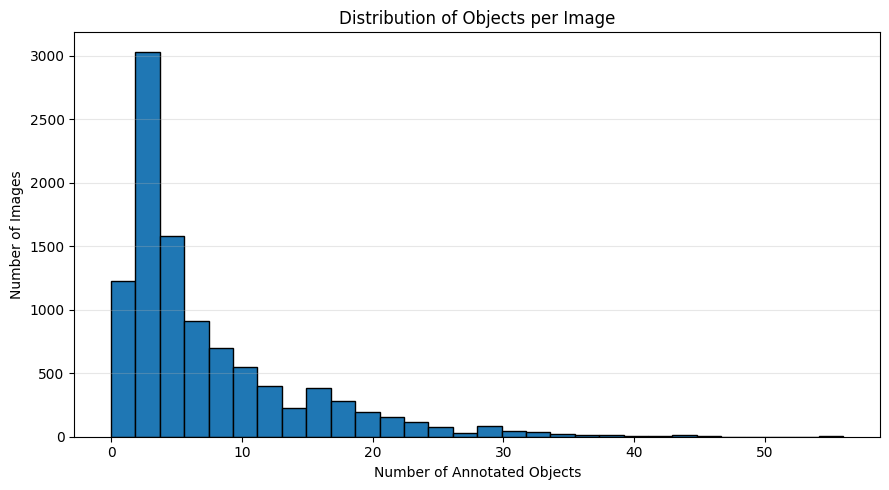


Visualization saved: /content/drive/MyDrive/COCO_Project/statistics/person3_scene_complexity.png
Scene complexity data saved in metadata.


In [ ]:
# ==========================================
# 10. SCENE COMPLEXITY ANALYSIS
# ==========================================

# Count objects in each selected image
objects_per_image = Counter(
    ann["image_id"] for ann in object_annotations
)

scene_df = pd.DataFrame({
    "image_id": selected_df["image_id"]
})

scene_df["object_count"] = (
    scene_df["image_id"]
    .map(objects_per_image)
    .fillna(0)
    .astype(int)
)

print("===== SCENE COMPLEXITY STATISTICS =====")
print(scene_df["object_count"].describe())

print("\nImages without object annotations:",
      (scene_df["object_count"] == 0).sum())

print("\nImages with 1-5 objects:",
      scene_df["object_count"].between(1, 5).sum())

print("Images with 6-10 objects:",
      scene_df["object_count"].between(6, 10).sum())

print("Images with more than 10 objects:",
      (scene_df["object_count"] > 10).sum())

# Histogram
plt.figure(figsize=(9, 5))

plt.hist(
    scene_df["object_count"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Objects per Image")
plt.xlabel("Number of Annotated Objects")
plt.ylabel("Number of Images")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plot_path = os.path.join(
    STATISTICS_DIR,
    "person3_scene_complexity.png"
)

plt.savefig(plot_path, dpi=300)
plt.show()

# Save results
scene_df.to_csv(
    os.path.join(METADATA_DIR, "person3_scene_complexity.csv"),
    index=False
)

print("\nVisualization saved:", plot_path)
print("Scene complexity data saved in metadata.")

Important: An image with zero object annotations is not necessarily empty. COCO may still provide captions describing its scene. We'll preserve those images.

Send me the output, then we'll review the preprocessing requirements and the remaining Phase 1 deliverables.

In [ ]:
# ==========================================
# 11. CREATE DATASET MANIFEST
# ==========================================

# Count captions per image
caption_counts = captions_df.groupby("image_id").size()

# Prepare image dimensions
manifest = selected_df.merge(
    dimensions_df[["id", "width", "height", "orientation"]],
    left_on="image_id",
    right_on="id",
    how="left"
)

manifest = manifest.drop(columns=["id"])

# Add caption counts
manifest["caption_count"] = (
    manifest["image_id"]
    .map(caption_counts)
    .fillna(0)
    .astype(int)
)

# Add object counts
manifest = manifest.merge(
    scene_df,
    on="image_id",
    how="left"
)

# Final checks
print("===== DATASET MANIFEST =====")
print("Total images:", len(manifest))
print("Missing dimensions:", manifest["width"].isna().sum())
print("Images without captions:", (manifest["caption_count"] == 0).sum())
print("Images without object annotations:",
      (manifest["object_count"] == 0).sum())

print("\nSplit distribution:")
print(manifest["split"].value_counts())

# Save in shared metadata folder
manifest_path = os.path.join(
    METADATA_DIR,
    "person3_clean_dataset_manifest.csv"
)

manifest.to_csv(manifest_path, index=False)

print("\nManifest saved:", manifest_path)
print("\nPreview:")
display(manifest.head())

===== DATASET MANIFEST =====
Total images: 10100
Missing dimensions: 0
Images without captions: 0
Images without object annotations: 104

Split distribution:
split
knowledge_base    10000
validation          100
Name: count, dtype: int64

Manifest saved: /content/drive/MyDrive/COCO_Project/metadata/person3_clean_dataset_manifest.csv

Preview:


,image_id,split,file_name,width,height,orientation,caption_count,object_count
0,411685,knowledge_base,000000411685.jpg,640,480,Landscape,5,2
1,71573,knowledge_base,000000071573.jpg,640,447,Landscape,5,4
2,16285,knowledge_base,000000016285.jpg,500,375,Landscape,5,5
3,478093,knowledge_base,000000478093.jpg,640,453,Landscape,5,1
4,177361,knowledge_base,000000177361.jpg,480,640,Portrait,5,2


In [ ]:
# ==========================================
# 12. CHECK TRANSFORMERS
# ==========================================

import importlib.util
import sys
import subprocess

if importlib.util.find_spec("transformers") is None:
    print("Installing Transformers...")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "transformers"
    ])
else:
    print("Transformers is already installed!")

import transformers

print("Transformers version:", transformers.__version__)
print("Environment ready for CLIP preprocessing.")

Transformers is already installed!
Transformers version: 5.22.0
Environment ready for CLIP preprocessing.


In [ ]:
# ==========================================
# 13. LOAD CLIP IMAGE PROCESSOR
# ==========================================

from transformers import CLIPImageProcessor

MODEL_NAME = "openai/clip-vit-base-patch32"

image_processor = CLIPImageProcessor.from_pretrained(MODEL_NAME)

print("===== CLIP PREPROCESSING CONFIGURATION =====")
print("Model:", MODEL_NAME)
print("Image size:", image_processor.size)
print("Crop size:", image_processor.crop_size)
print("RGB conversion:", image_processor.do_convert_rgb)
print("Rescaling:", image_processor.do_rescale)
print("Normalization:", image_processor.do_normalize)
print("Mean:", image_processor.image_mean)
print("Standard deviation:", image_processor.image_std)

print("\nCLIP image processor loaded successfully!")

===== CLIP PREPROCESSING CONFIGURATION =====
Model: openai/clip-vit-base-patch32
Image size: SizeDict(height=None, width=None, longest_edge=None, shortest_edge=224, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
Crop size: SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
RGB conversion: True
Rescaling: True
Normalization: True
Mean: (0.48145466, 0.4578275, 0.40821073)
Standard deviation: (0.26862954, 0.26130258, 0.27577711)

CLIP image processor loaded successfully!


Original image size: (640, 480)

===== PREPROCESSING RESULT =====
Tensor shape: (1, 3, 224, 224)
Data type: torch.float32
Minimum value: -1.7922625541687012
Maximum value: 1.9468162059783936


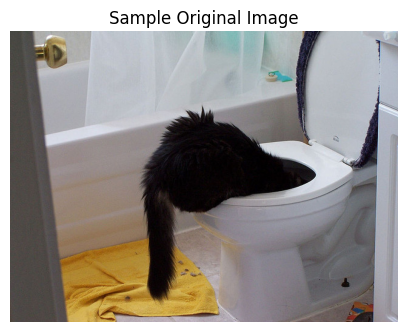

In [ ]:
# ==========================================
# 14. TEST CLIP IMAGE PREPROCESSING
# ==========================================

# Select one knowledge-base image
sample = selected_df[
    selected_df["split"] == "knowledge_base"
].iloc[0]

sample_path = os.path.join(
    IMAGES_DIR,
    sample["split"],
    sample["file_name"]
)

# Open image
sample_image = Image.open(sample_path).convert("RGB")

print("Original image size:", sample_image.size)

# Apply CLIP preprocessing
processed = image_processor(
    images=sample_image,
    return_tensors="pt"
)

pixel_values = processed["pixel_values"]

print("\n===== PREPROCESSING RESULT =====")
print("Tensor shape:", tuple(pixel_values.shape))
print("Data type:", pixel_values.dtype)
print("Minimum value:", pixel_values.min().item())
print("Maximum value:", pixel_values.max().item())

# Display original image
plt.figure(figsize=(5, 5))
plt.imshow(sample_image)
plt.title("Sample Original Image")
plt.axis("off")
plt.show()

In [ ]:
# ==========================================
# 15. SAVE CLIP PREPROCESSING CONFIGURATION
# ==========================================

preprocessing_report = {
    "model": MODEL_NAME,
    "processor": "CLIPImageProcessor",
    "resize": image_processor.size,
    "crop_size": image_processor.crop_size,
    "rgb_conversion": image_processor.do_convert_rgb,
    "rescaling": image_processor.do_rescale,
    "normalization": image_processor.do_normalize,
    "image_mean": list(image_processor.image_mean),
    "image_std": list(image_processor.image_std),
    "output_tensor_shape": list(pixel_values.shape),
    "output_dtype": str(pixel_values.dtype),
    "test_status": "successful",
    "original_images_modified": False
}

# Convert SizeDict objects into JSON-compatible dictionaries
preprocessing_report["resize"] = dict(preprocessing_report["resize"])
preprocessing_report["crop_size"] = dict(preprocessing_report["crop_size"])

report_path = os.path.join(
    METADATA_DIR,
    "person3_clip_preprocessing_config.json"
)

with open(report_path, "w") as f:
    json.dump(preprocessing_report, f, indent=4)

print("Preprocessing configuration saved!")
print(report_path)

Preprocessing configuration saved!
/content/drive/MyDrive/COCO_Project/metadata/person3_clip_preprocessing_config.json


In [ ]:
# ==========================================
# 18. PREPARE TEST DATASET FOLDERS
# ==========================================

TEST_DIR = os.path.join(BASE_DIR, "test")
TEST_IMAGES_DIR = os.path.join(TEST_DIR, "val2017")

os.makedirs(TEST_IMAGES_DIR, exist_ok=True)

print("Test folder prepared:")
print(TEST_DIR)

print("\nTest images folder prepared:")
print(TEST_IMAGES_DIR)

Test folder prepared:
/content/drive/MyDrive/COCO_Project/test

Test images folder prepared:
/content/drive/MyDrive/COCO_Project/test/val2017


In [ ]:
# ==========================================
# 19. DOWNLOAD COCO VAL2017 CAPTIONS
# ==========================================

import urllib.request

CAPTIONS_VAL_PATH = os.path.join(
    ANNOTATIONS_DIR,
    "captions_val2017.json"
)

CAPTIONS_VAL_URL = (
    "https://huggingface.co/datasets/merve/coco/"
    "resolve/main/annotations/captions_val2017.json"
)

if not os.path.exists(CAPTIONS_VAL_PATH):
    print("Downloading COCO validation captions...")

    urllib.request.urlretrieve(
        CAPTIONS_VAL_URL,
        CAPTIONS_VAL_PATH
    )
else:
    print("Caption file already exists. Skipping download.")

# Load and inspect
with open(CAPTIONS_VAL_PATH, "r") as f:
    val_captions_data = json.load(f)

print("\n===== VAL2017 CAPTIONS =====")
print("Images:", len(val_captions_data["images"]))
print("Captions:", len(val_captions_data["annotations"]))
print("Categories:", len(val_captions_data.get("categories", [])))

print("\nSample image:")
print(val_captions_data["images"][0])

print("\nSample caption:")
print(val_captions_data["annotations"][0]["caption"])

print("\nSaved:", CAPTIONS_VAL_PATH)

Caption file already exists. Skipping download.

===== VAL2017 CAPTIONS =====
Images: 5000
Captions: 25014
Categories: 0

Sample image:
{'license': 4, 'file_name': '000000397133.jpg', 'coco_url': 'http://images.cocodataset.org/val2017/000000397133.jpg', 'height': 427, 'width': 640, 'date_captured': '2013-11-14 17:02:52', 'flickr_url': 'http://farm7.staticflickr.com/6116/6255196340_da26cf2c9e_z.jpg', 'id': 397133}

Sample caption:
A black Honda motorcycle parked in front of a garage.

Saved: /content/drive/MyDrive/COCO_Project/annotations/captions_val2017.json


In [ ]:
# ==========================================
# 20. SELECT 100 INDEPENDENT TEST IMAGES
# ==========================================

import random

# All available validation image records
val_images = val_captions_data["images"]

# Existing train2017 image IDs
existing_ids = set(selected_df["image_id"])

# Keep only IDs that do not overlap
available_images = [
    img for img in val_images
    if img["id"] not in existing_ids
]

# Reproducible random selection
random.seed(42)
test_images = random.sample(available_images, 100)

# Create test manifest
test_df = pd.DataFrame([
    {
        "image_id": img["id"],
        "file_name": img["file_name"],
        "width": img["width"],
        "height": img["height"],
        "split": "test"
    }
    for img in test_images
])

# Verify selection
test_ids = set(test_df["image_id"])
overlap = test_ids.intersection(existing_ids)

print("===== TEST SET SELECTION =====")
print("Available validation images:", len(available_images))
print("Selected test images:", len(test_df))
print("Overlap with existing dataset:", len(overlap))
print("Unique test IDs:", test_df["image_id"].nunique())

# Save manifest
test_manifest_path = os.path.join(
    METADATA_DIR,
    "person3_test100_manifest.csv"
)

test_df.to_csv(test_manifest_path, index=False)

print("\nTest manifest saved:", test_manifest_path)
display(test_df.head())

===== TEST SET SELECTION =====
Available validation images: 5000
Selected test images: 100
Overlap with existing dataset: 0
Unique test IDs: 100

Test manifest saved: /content/drive/MyDrive/COCO_Project/metadata/person3_test100_manifest.csv


,image_id,file_name,width,height,split
0,301061,000000301061.jpg,480,640,test
1,261982,000000261982.jpg,457,640,test
2,273760,000000273760.jpg,467,640,test
3,248400,000000248400.jpg,640,427,test
4,382030,000000382030.jpg,500,375,test


In [ ]:
# ==========================================
# 21. DOWNLOAD 100 TEST IMAGES
# ==========================================

import requests
import shutil
from concurrent.futures import ThreadPoolExecutor, as_completed

# Load manifest if necessary
test_df = pd.read_csv(
    os.path.join(METADATA_DIR, "person3_test100_manifest.csv")
)

TEMP_TEST_DIR = "/content/coco_val2017_test"
os.makedirs(TEMP_TEST_DIR, exist_ok=True)
os.makedirs(TEST_IMAGES_DIR, exist_ok=True)

def download_image(filename):
    local_path = os.path.join(TEMP_TEST_DIR, filename)

    if os.path.exists(local_path) and os.path.getsize(local_path) > 0:
        return filename, "Already downloaded"

    url = f"https://images.cocodataset.org/val2017/{filename}"

    for attempt in range(3):
        try:
            response = requests.get(url, timeout=30)
            response.raise_for_status()

            with open(local_path, "wb") as f:
                f.write(response.content)

            return filename, "Downloaded"

        except Exception as e:
            if attempt == 2:
                return filename, str(e)

# Download using 8 parallel workers
results = []

with ThreadPoolExecutor(max_workers=8) as executor:
    futures = [
        executor.submit(download_image, filename)
        for filename in test_df["file_name"]
    ]

    for future in tqdm(as_completed(futures), total=len(futures)):
        results.append(future.result())

# Copy successful downloads to shared Drive
downloaded = []
failed = []

for filename, status in results:
    local_path = os.path.join(TEMP_TEST_DIR, filename)
    drive_path = os.path.join(TEST_IMAGES_DIR, filename)

    if os.path.isfile(local_path) and os.path.getsize(local_path) > 0:
        shutil.copy2(local_path, drive_path)
        downloaded.append(filename)
    else:
        failed.append((filename, status))

print("\n===== DOWNLOAD REPORT =====")
print("Expected images:", len(test_df))
print("Copied to shared Drive:", len(downloaded))
print("Failed:", len(failed))

if failed:
    print("\nFailed downloads:")
    print(failed[:10])

print("\nTest image folder:", TEST_IMAGES_DIR)

  0%|          | 0/100 [00:00<?, ?it/s]


===== DOWNLOAD REPORT =====
Expected images: 100
Copied to shared Drive: 100
Failed: 0

Test image folder: /content/drive/MyDrive/COCO_Project/test/val2017


In [ ]:
# ==========================================
# 22. TEST HUGGING FACE IMAGE DOWNLOAD
# ==========================================

import requests
from io import BytesIO

sample_filename = test_df.iloc[0]["file_name"]

url = (
    "https://huggingface.co/datasets/merve/coco/"
    f"resolve/main/val2017/{sample_filename}"
)

response = requests.get(url, timeout=60)
response.raise_for_status()

test_image = Image.open(BytesIO(response.content))
test_image.verify()

print("===== DOWNLOAD TEST =====")
print("Filename:", sample_filename)
print("HTTP status:", response.status_code)
print("Downloaded size:", len(response.content), "bytes")
print("Image format: JPEG")
print("Image verification: successful")

===== DOWNLOAD TEST =====
Filename: 000000301061.jpg
HTTP status: 200
Downloaded size: 158066 bytes
Image format: JPEG
Image verification: successful


In [ ]:
# ==========================================
# 23. DOWNLOAD ALL 100 TEST IMAGES
# ==========================================

import requests
import shutil
from io import BytesIO
from concurrent.futures import ThreadPoolExecutor, as_completed

TEMP_TEST_DIR = "/content/coco_val2017_test"
os.makedirs(TEMP_TEST_DIR, exist_ok=True)
os.makedirs(TEST_IMAGES_DIR, exist_ok=True)

def download_test_image(filename):

    url = (
        "https://huggingface.co/datasets/merve/coco/"
        f"resolve/main/val2017/{filename}"
    )

    local_path = os.path.join(TEMP_TEST_DIR, filename)

    for attempt in range(3):
        try:
            response = requests.get(url, timeout=60)
            response.raise_for_status()

            image = Image.open(BytesIO(response.content))
            image.verify()

            with open(local_path, "wb") as f:
                f.write(response.content)

            return filename, "Success"

        except Exception as e:
            if attempt == 2:
                return filename, str(e)

# Download images in parallel
results = []

with ThreadPoolExecutor(max_workers=6) as executor:

    futures = [
        executor.submit(download_test_image, filename)
        for filename in test_df["file_name"]
    ]

    for future in tqdm(as_completed(futures), total=len(futures)):
        results.append(future.result())

# Copy verified images to shared Drive
successful = []
failed = []

for filename, status in results:

    local_path = os.path.join(TEMP_TEST_DIR, filename)

    if status == "Success" and os.path.isfile(local_path):
        drive_path = os.path.join(TEST_IMAGES_DIR, filename)
        shutil.copy2(local_path, drive_path)
        successful.append(filename)
    else:
        failed.append((filename, status))

print("\n===== FINAL DOWNLOAD REPORT =====")
print("Expected:", len(test_df))
print("Successfully copied:", len(successful))
print("Failed:", len(failed))

print("\nShared Drive folder:")
print(TEST_IMAGES_DIR)

if failed:
    print("\nFailed files:")
    print(failed[:10])

  0%|          | 0/100 [00:00<?, ?it/s]


===== FINAL DOWNLOAD REPORT =====
Expected: 100
Successfully copied: 100
Failed: 0

Shared Drive folder:
/content/drive/MyDrive/COCO_Project/test/val2017


In [ ]:
# ==========================================
# 24. VERIFY TEST IMAGES AND EXTRACT CAPTIONS
# ==========================================

import json
import os
import pandas as pd
from PIL import Image
from collections import Counter

# Load captions if the variable is not already available
if "val_captions_data" not in globals():
    captions_path = os.path.join(
        ANNOTATIONS_DIR, "captions_val2017.json"
    )
    with open(captions_path, "r") as f:
        val_captions_data = json.load(f)

# Reload test manifest if necessary
if "test_df" not in globals():
    test_df = pd.read_csv(
        os.path.join(METADATA_DIR, "person3_test100_manifest.csv")
    )

# Verify all 100 images
valid_images = []
invalid_images = []

for filename in test_df["file_name"]:
    image_path = os.path.join(TEST_IMAGES_DIR, filename)

    try:
        with Image.open(image_path) as img:
            img.verify()
        valid_images.append(filename)
    except Exception as e:
        invalid_images.append((filename, str(e)))

# Extract captions belonging only to our 100 test images
test_ids = set(test_df["image_id"].astype(int))

test_images_metadata = [
    img for img in val_captions_data["images"]
    if img["id"] in test_ids
]

test_annotations = [
    ann for ann in val_captions_data["annotations"]
    if ann["image_id"] in test_ids
]

# Build a separate COCO-format test captions file
test_captions_data = {
    "info": val_captions_data.get("info", {}),
    "licenses": val_captions_data.get("licenses", []),
    "images": test_images_metadata,
    "annotations": test_annotations
}

output_path = os.path.join(
    ANNOTATIONS_DIR, "captions_test100.json"
)

with open(output_path, "w") as f:
    json.dump(test_captions_data, f, indent=2)

# Caption count per image
caption_counts = Counter(
    ann["image_id"] for ann in test_annotations
)

test_df["caption_count"] = (
    test_df["image_id"].astype(int).map(caption_counts).fillna(0).astype(int)
)

manifest_path = os.path.join(
    METADATA_DIR, "person3_test100_manifest.csv"
)

test_df.to_csv(manifest_path, index=False)

print("===== TEST DATASET VERIFICATION =====")
print("Expected images:", len(test_df))
print("Valid images:", len(valid_images))
print("Invalid images:", len(invalid_images))
print("Unique test image IDs:", len(test_ids))
print("Images in captions file:", len(test_images_metadata))
print("Total test captions:", len(test_annotations))
print("Images without captions:", (test_df["caption_count"] == 0).sum())

print("\nSaved captions:", output_path)
print("Updated manifest:", manifest_path)

===== TEST DATASET VERIFICATION =====
Expected images: 100
Valid images: 100
Invalid images: 0
Unique test image IDs: 100
Images in captions file: 100
Total test captions: 500
Images without captions: 0

Saved captions: /content/drive/MyDrive/COCO_Project/annotations/captions_test100.json
Updated manifest: /content/drive/MyDrive/COCO_Project/metadata/person3_test100_manifest.csv


In [ ]:
# ==========================================
# 25. FINAL SPLIT INTEGRITY CHECK
# ==========================================

train_ids = set(
    selected_df.loc[
        selected_df["split"] == "knowledge_base", "image_id"
    ].astype(int)
)

validation_ids = set(
    selected_df.loc[
        selected_df["split"] == "validation", "image_id"
    ].astype(int)
)

test_ids = set(test_df["image_id"].astype(int))

print("===== SPLIT INTEGRITY REPORT =====")

print("Knowledge base:", len(train_ids))
print("Validation:", len(validation_ids))
print("Test:", len(test_ids))

print("\n===== OVERLAP CHECK =====")

print("Train ∩ Validation:", len(train_ids & validation_ids))
print("Train ∩ Test:", len(train_ids & test_ids))
print("Validation ∩ Test:", len(validation_ids & test_ids))

print("\n===== FINAL STATUS =====")

if (
    len(train_ids) == 10000
    and len(validation_ids) == 100
    and len(test_ids) == 100
    and not (train_ids & validation_ids)
    and not (train_ids & test_ids)
    and not (validation_ids & test_ids)
):
    print("SUCCESS: All three splits are separate and valid.")
else:
    print("WARNING: Review the split counts or overlaps.")

===== SPLIT INTEGRITY REPORT =====
Knowledge base: 10000
Validation: 100
Test: 100

===== OVERLAP CHECK =====
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

===== FINAL STATUS =====
SUCCESS: All three splits are separate and valid.


In [ ]:
# ==========================================
# 26. SAVE PERSON 3 FINAL REPORT
# ==========================================

person3_report = {
    "responsible_person": "Person 3",
    "phase": "Phase 1",
    "dataset": "MS COCO 2017",

    "splits": {
        "knowledge_base": 10000,
        "validation": 100,
        "test": 100,
        "total": 10200,
        "overlap": 0
    },

    "integrity": {
        "knowledge_base_validation_images": 10100,
        "test_images": 100,
        "corrupted_images": 0,
        "missing_test_images": 0,
        "duplicate_groups": 0,
        "all_test_images_verified": True
    },

    "captions": {
        "test_images_with_captions": 100,
        "test_reference_captions": 500,
        "test_images_without_captions": 0
    },

    "preprocessing": {
        "model": "openai/clip-vit-base-patch32",
        "image_size": [224, 224],
        "output_shape": [1, 3, 224, 224],
        "preprocessing_test": "successful"
    },

    "analysis_outputs": [
        "person3_split_distribution.png",
        "person3_image_orientation.png",
        "person3_caption_length_distribution.png",
        "person3_object_category_distribution.png",
        "person3_scene_complexity.png"
    ],

    "status": "Phase 1 data preparation completed",
    "pending": [
        "Coordinate embedding generation with Person 4",
        "Confirm validation split interpretation with the team"
    ]
}

report_path = os.path.join(
    METADATA_DIR, "person3_final_report.json"
)

with open(report_path, "w") as f:
    json.dump(person3_report, f, indent=4)

print("Final report saved successfully!")
print(report_path)

Final report saved successfully!
/content/drive/MyDrive/COCO_Project/metadata/person3_final_report.json
